In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully")

Dataset loaded successfully


In [ ]:
print("First five records:")
display(df.head())

print("Last five records:")
display(df.tail())

First five records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Last five records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [ ]:
print("Dataset Shape:", df.shape)

print("Number of Rows:", df.shape[0])

print("Number of Columns:", df.shape[1])

Dataset Shape: (891, 15)
Number of Rows: 891
Number of Columns: 15


In [ ]:
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

Data Types:
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        

In [ ]:
numerical = df.select_dtypes(include=np.number)

categorical = df.select_dtypes(include='object')

print("Numerical Columns:")
print(numerical.columns.tolist())

print("\nCategorical Columns:")
print(categorical.columns.tolist())

Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'deck', 'embark_town', 'alive']


In [ ]:
print(df.describe())

         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


In [ ]:
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [ ]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})

print(missing)

             Missing Values  Percentage
survived                  0    0.000000
pclass                    0    0.000000
sex                       0    0.000000
age                     177   19.865320
sibsp                     0    0.000000
parch                     0    0.000000
fare                      0    0.000000
embarked                  2    0.224467
class                     0    0.000000
who                       0    0.000000
adult_male                0    0.000000
deck                    688   77.216611
embark_town               2    0.224467
alive                     0    0.000000
alone                     0    0.000000


In [ ]:
df_clean = df.copy()

In [ ]:
df_clean['age'] = df_clean['age'].fillna(
    df_clean['age'].median()
)

df_clean['embarked'] = df_clean['embarked'].fillna(
    df_clean['embarked'].mode()[0]
)

df_clean = df_clean.drop(columns=['deck'])

print(df_clean.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


In [ ]:
print("Duplicate Rows:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicates After Cleaning:",
      df_clean.duplicated().sum())

Duplicate Rows: 116
Duplicates After Cleaning: 0


In [ ]:
print(df_clean['sex'].unique())

print(df_clean['embarked'].unique())

['male' 'female']
['S' 'C' 'Q']


In [ ]:
df_clean['sex'] = df_clean['sex'].str.strip().str.lower()

df_clean['embarked'] = df_clean['embarked'].str.strip().str.upper()

In [ ]:
print(df_clean.describe())

         survived      pclass         age       sibsp       parch        fare
count  775.000000  775.000000  775.000000  775.000000  775.000000  775.000000
mean     0.412903    2.246452   29.581187    0.529032    0.420645   34.878403
std      0.492674    0.853574   13.766359    0.990326    0.840565   52.408474
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    1.000000   21.000000    0.000000    0.000000    8.050000
50%      0.000000    3.000000   28.000000    0.000000    0.000000   15.900000
75%      1.000000    3.000000   36.000000    1.000000    1.000000   34.197900
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


In [ ]:
print(df_clean['sex'].value_counts())

sex
male      483
female    292
Name: count, dtype: int64


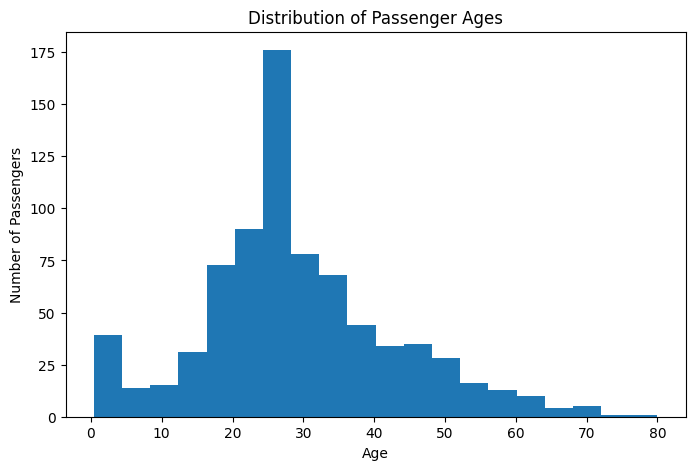

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df_clean['age'], bins=20)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

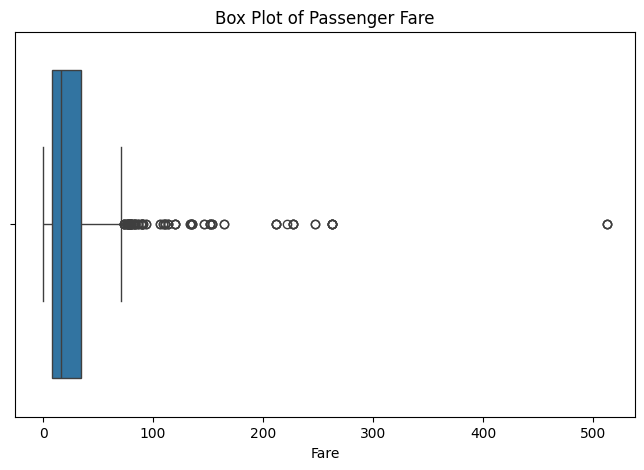

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df_clean['fare'])

plt.title("Box Plot of Passenger Fare")
plt.xlabel("Fare")

plt.show()

In [ ]:
df_clean = df_clean.drop(
    columns=['alive', 'class', 'who',
             'adult_male', 'embark_town']
)

df_clean = pd.get_dummies(
    df_clean,
    columns=['sex', 'embarked'],
    drop_first=True,
    dtype=int
)

print(df_clean.head())

   survived  pclass   age  sibsp  parch     fare  alone  sex_male  embarked_Q  \
0         0       3  22.0      1      0   7.2500  False         1           0   
1         1       1  38.0      1      0  71.2833  False         0           0   
2         1       3  26.0      0      0   7.9250   True         0           0   
3         1       1  35.0      1      0  53.1000  False         0           0   
4         0       3  35.0      0      0   8.0500   True         1           0   

   embarked_S  
0           1  
1           0  
2           1  
3           1  
4           1  


In [ ]:
scaler = StandardScaler()

scale_columns = ['age', 'fare']

df_clean[scale_columns] = scaler.fit_transform(
    df_clean[scale_columns]
)

print(df_clean.head())

   survived  pclass       age  sibsp  parch      fare  alone  sex_male  \
0         0       3 -0.551060      1      0 -0.527515  False         1   
1         1       1  0.611945      1      0  0.695086  False         0   
2         1       3 -0.260308      0      0 -0.514627   True         0   
3         1       1  0.393881      1      0  0.347909  False         0   
4         0       3  0.393881      0      0 -0.512240   True         1   

   embarked_Q  embarked_S  
0           0           1  
1           0           0  
2           0           1  
3           0           1  
4           0           1  


In [ ]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

display(df_clean.head())

Final Dataset Shape: (775, 10)

Missing Values:
survived      0
pclass        0
age           0
sibsp         0
parch         0
fare          0
alone         0
sex_male      0
embarked_Q    0
embarked_S    0
dtype: int64

Duplicate Rows:
0


,survived,pclass,age,sibsp,parch,fare,alone,sex_male,embarked_Q,embarked_S
0,0,3,-0.551060,1,0,-0.527515,False,1,0,1
1,1,1,0.611945,1,0,0.695086,False,0,0,0
2,1,3,-0.260308,0,0,-0.514627,True,0,0,1
3,1,1,0.393881,1,0,0.347909,False,0,0,1
4,0,3,0.393881,0,0,-0.512240,True,1,0,1


In [ ]:
df_clean.to_csv(
    'titanic_prepared.csv',
    index=False
)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!


In [ ]:
from google.colab import files

files.download('titanic_prepared.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>